# Ekstraksi Fitur Manual Daun Cabai
Input: hasil segmentasi (`Dataset/segmentasi`). Semua fitur dihitung **manual dengan NumPy**; OpenCV hanya untuk membaca/resize gambar.

Alur: **Load → Warna → Tekstur (GLCM) → Ekstraksi semua data → Bandingkan 3 kelas**

Di tiap tahap ada gambar contoh dari 3 kelas supaya kelihatan fitur mana yang membedakan kelas.

In [1]:
import os, numpy as np, cv2, pandas as pd
import matplotlib.pyplot as plt

# ============ KONFIGURASI ============
ROOT = os.path.join("Dataset", "segmentasi")
SUMBER = ["train_asli", "train_aug"]
OUT_DIR = os.path.join("Dataset", "ekstraksi_fitur_v2")   # CSV: fitur_train_asli.csv & fitur_train_aug.csv
KELAS = ["Daunsehat", "Leafcurl", "yelowwiss"]
UKURAN = 224        # resize seragam
THRESH = 10         # piksel > THRESH dianggap daun (background hitam)
LEVEL = 16          # level kuantisasi GLCM
EXT = (".png", ".jpg", ".jpeg", ".bmp")
WARNA_KELAS = {"Daunsehat": "tab:green", "Leafcurl": "tab:blue", "yelowwiss": "goldenrod"}

## 0. Fungsi-fungsi (manual)

In [2]:
def baca(path):
    """Baca gambar -> RGB ukuran seragam + mask daun."""
    bgr = cv2.imread(path)
    if bgr is None:
        return None, None
    rgb = np.ascontiguousarray(bgr[..., ::-1])               # BGR -> RGB
    rgb = cv2.resize(rgb, (UKURAN, UKURAN), interpolation=cv2.INTER_NEAREST)
    mask = rgb.max(axis=2) > THRESH                          # True = daun
    return rgb, mask

def rgb_ke_hsv(rgb):
    """RGB -> HSV manual. H: 0-360, S: 0-1, V: 0-1."""
    r, g, b = [rgb[..., i].astype(np.float64) / 255.0 for i in range(3)]
    mx = np.maximum(np.maximum(r, g), b)
    mn = np.minimum(np.minimum(r, g), b)
    d = mx - mn
    h = np.zeros_like(mx)
    nz = d > 1e-12
    m_r = nz & (mx == r)
    m_g = nz & (mx == g) & ~m_r
    m_b = nz & ~m_r & ~m_g
    h[m_r] = (60 * ((g[m_r] - b[m_r]) / d[m_r])) % 360
    h[m_g] = 60 * ((b[m_g] - r[m_g]) / d[m_g]) + 120
    h[m_b] = 60 * ((r[m_b] - g[m_b]) / d[m_b]) + 240
    s = np.zeros_like(mx)
    pos = mx > 1e-12
    s[pos] = d[pos] / mx[pos]
    return h, s, mx

def stat_channel(x):
    mean, std = x.mean(), x.std()
    skew = 0.0 if std < 1e-12 else np.mean(((x - mean) / std) ** 3)
    return mean, std, skew

def fitur_warna(rgb, mask):
    h, s, v = rgb_ke_hsv(rgb)
    kanal = {"R": rgb[..., 0].astype(float), "G": rgb[..., 1].astype(float),
             "B": rgb[..., 2].astype(float), "H": h, "S": s, "V": v}
    out = {}
    for nama, arr in kanal.items():
        m, sd, sk = stat_channel(arr[mask])
        out[f"{nama}_mean"], out[f"{nama}_std"], out[f"{nama}_skew"] = m, sd, sk
    return out

def ke_gray_kuantisasi(rgb):
    gray = 0.299 * rgb[..., 0] + 0.587 * rgb[..., 1] + 0.114 * rgb[..., 2]
    q = np.clip((gray * LEVEL / 256.0).astype(np.int64), 0, LEVEL - 1)
    return gray, q

def glcm(q, mask, dy, dx, level=LEVEL):
    """GLCM simetris & ternormalisasi; hanya pasangan piksel yang keduanya daun."""
    H, W = q.shape
    y0, y1 = max(0, -dy), H - max(0, dy)
    x0, x1 = max(0, -dx), W - max(0, dx)
    a = q[y0:y1, x0:x1]
    b = q[y0+dy:y1+dy, x0+dx:x1+dx]
    valid = mask[y0:y1, x0:x1] & mask[y0+dy:y1+dy, x0+dx:x1+dx]
    idx = a[valid] * level + b[valid]
    P = np.bincount(idx, minlength=level*level).reshape(level, level).astype(float)
    P = P + P.T
    return P / P.sum() if P.sum() > 0 else P

def fitur_dari_glcm(P):
    L = P.shape[0]
    i, j = np.meshgrid(np.arange(L), np.arange(L), indexing="ij")
    contrast = np.sum(P * (i - j) ** 2)
    homogeneity = np.sum(P / (1.0 + (i - j) ** 2))
    energy = np.sum(P ** 2)
    mu_i, mu_j = np.sum(i * P), np.sum(j * P)
    sd_i = np.sqrt(np.sum(P * (i - mu_i) ** 2))
    sd_j = np.sqrt(np.sum(P * (j - mu_j) ** 2))
    corr = 0.0 if sd_i < 1e-12 or sd_j < 1e-12 else np.sum(P * (i - mu_i) * (j - mu_j)) / (sd_i * sd_j)
    nz = P > 0
    entropy = -np.sum(P[nz] * np.log2(P[nz]))
    return np.array([contrast, homogeneity, energy, corr, entropy])

ARAH = [(0, 1), (-1, 1), (-1, 0), (-1, -1)]   # 0, 45, 90, 135 derajat (jarak 1)
NAMA_GLCM = ["contrast", "homogeneity", "energy", "correlation", "entropy"]

def fitur_tekstur(rgb, mask):
    _, q = ke_gray_kuantisasi(rgb)
    semua = np.array([fitur_dari_glcm(glcm(q, mask, dy, dx)) for dy, dx in ARAH])
    return {f"glcm_{n}": v for n, v in zip(NAMA_GLCM, semua.mean(axis=0))}

def erosi(mask):
    p = np.pad(mask, 1, constant_values=False)
    return p[1:-1, 1:-1] & p[:-2, 1:-1] & p[2:, 1:-1] & p[1:-1, :-2] & p[1:-1, 2:]


def kumpulkan(sumber):
    """List (path, label) di ROOT/sumber; label = nama folder induk."""
    hasil = []
    folder = os.path.join(ROOT, sumber)
    for dp, _, files in os.walk(folder):
        if dp == folder:
            continue
        for fn in sorted(files):
            if fn.lower().endswith(EXT):
                hasil.append((os.path.join(dp, fn), os.path.basename(dp)))
    return hasil

## 1. Load contoh gambar tiap kelas
Diambil 1 gambar per kelas dari `train_asli`. Ganti `INDEKS` untuk melihat gambar lain.

Daunsehat: 115 gambar di train_asli
Leafcurl: 42 gambar di train_asli
yelowwiss: 5 gambar di train_asli


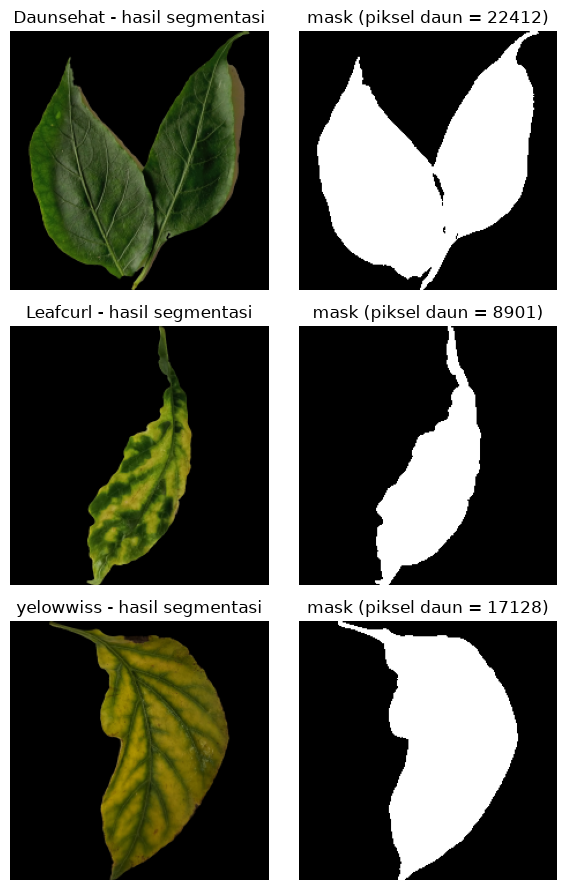

In [3]:
INDEKS = 0   # ganti angka ini untuk contoh gambar yang berbeda

daftar = kumpulkan("train_asli")
contoh = {}
for k in KELAS:
    paths = [p for p, l in daftar if l == k]
    print(f"{k}: {len(paths)} gambar di train_asli")
    contoh[k] = paths[min(INDEKS, len(paths) - 1)]

data = {k: baca(p) for k, p in contoh.items()}   # {kelas: (rgb, mask)}

fig, ax = plt.subplots(3, 2, figsize=(6, 9))
for r, k in enumerate(KELAS):
    rgb, mask = data[k]
    ax[r, 0].imshow(rgb);  ax[r, 0].set_title(f"{k} - hasil segmentasi")
    ax[r, 1].imshow(mask, cmap="gray"); ax[r, 1].set_title(f"mask (piksel daun = {mask.sum()})")
    ax[r, 0].axis("off"); ax[r, 1].axis("off")
plt.tight_layout(); plt.show()

## 2. Fitur WARNA
Fitur dihitung **hanya di piksel daun** (background hitam diabaikan, kalau tidak rata-rata warna jadi salah).

Yang diharapkan: **yelowwiss** kekuningan → Hue lebih kecil (mendekati 60°) dibanding daun hijau (±100-140°), dan Saturasi/Value berbeda.

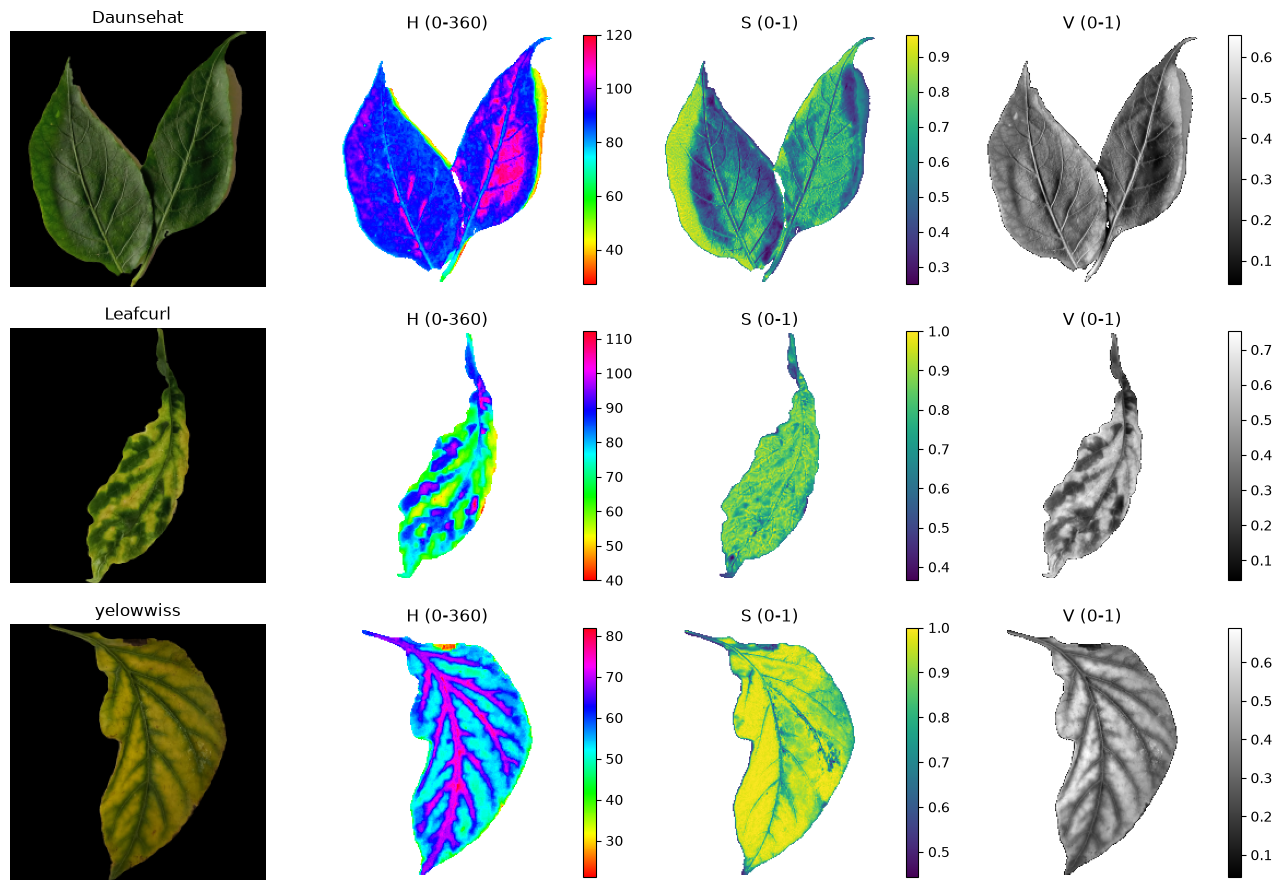

In [4]:
# 2a. Pecah gambar jadi kanal H, S, V (background di-mask supaya tidak ikut)
fig, ax = plt.subplots(3, 4, figsize=(13, 9))
for r, k in enumerate(KELAS):
    rgb, mask = data[k]
    h, s, v = rgb_ke_hsv(rgb)
    ax[r, 0].imshow(rgb); ax[r, 0].set_title(k)
    for c, (nm, arr, cm) in enumerate([("H (0-360)", h, "hsv"), ("S (0-1)", s, "viridis"), ("V (0-1)", v, "gray")], 1):
        im = ax[r, c].imshow(np.where(mask, arr, np.nan), cmap=cm)
        ax[r, c].set_title(nm); plt.colorbar(im, ax=ax[r, c], fraction=0.046)
    for a in ax[r]: a.axis("off")
plt.tight_layout(); plt.show()

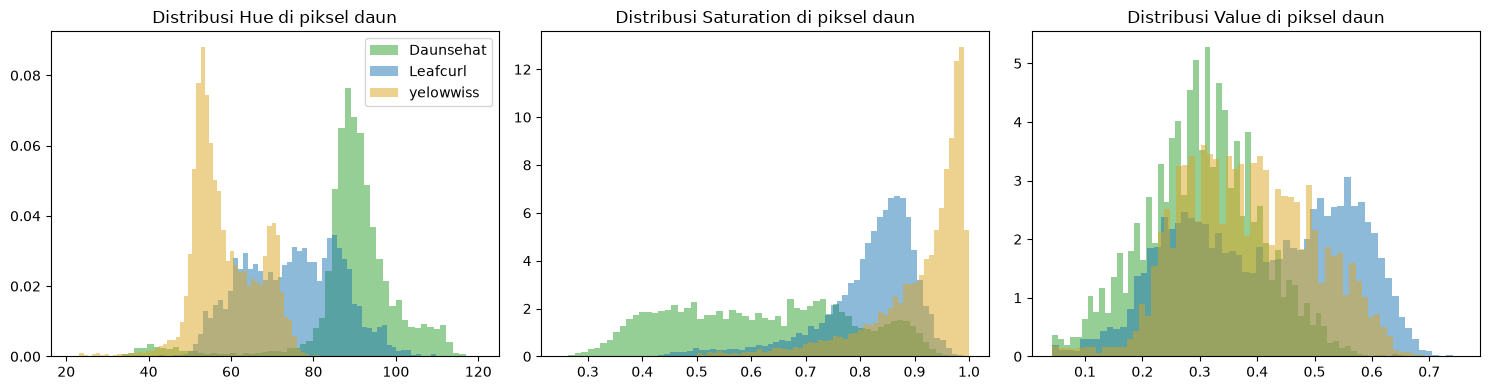

,R_mean,R_std,R_skew,G_mean,G_std,G_skew,B_mean,B_std,B_skew,H_mean,H_std,H_skew,S_mean,S_std,S_skew,V_mean,V_std,V_skew
Daunsehat,55.129,26.197,0.368,77.054,24.848,0.006,31.632,20.877,0.735,89.400,12.353,-1.950,0.617,0.164,0.051,0.304,0.098,-0.019
Leafcurl,87.525,42.858,0.147,104.061,36.114,-0.200,19.039,11.895,1.979,74.923,11.702,-0.000,0.815,0.093,-1.529,0.411,0.145,-0.159
yelowwiss,94.670,31.402,0.008,90.422,23.692,-0.273,7.869,7.475,1.833,58.535,8.133,0.027,0.909,0.093,-1.773,0.382,0.113,0.050


In [5]:
# 2b. Distribusi nilai H, S, V di piksel daun (histogram dihitung oleh matplotlib hanya untuk tampilan)
fig, ax = plt.subplots(1, 3, figsize=(15, 4))
for k in KELAS:
    rgb, mask = data[k]
    h, s, v = rgb_ke_hsv(rgb)
    for a, arr, nm in zip(ax, [h, s, v], ["Hue", "Saturation", "Value"]):
        a.hist(arr[mask], bins=60, alpha=0.5, label=k, color=WARNA_KELAS[k], density=True)
        a.set_title(f"Distribusi {nm} di piksel daun")
ax[0].legend(); plt.tight_layout(); plt.show()

# 2c. Nilai fitur warna ketiga contoh
tabel_warna = pd.DataFrame({k: fitur_warna(*data[k]) for k in KELAS}).T
tabel_warna.round(3)

**Cara baca:** kalau puncak histogram Hue tiap kelas berada di posisi berbeda, fitur `H_mean` bagus untuk membedakan kelas. Kalau tumpang tindih, fitur itu kurang berguna sendirian.

## 3. Fitur TEKSTUR (GLCM manual)
Langkah: RGB → grayscale (`0.299R+0.587G+0.114B`) → kuantisasi 16 level → hitung matriks co-occurrence (pasangan piksel bertetangga) → ambil statistik.

- **contrast** tinggi = perbedaan intensitas antar tetangga besar (permukaan kasar/bercak)
- **homogeneity** tinggi = tetangga mirip (halus)
- **energy** tinggi = pola seragam
- **entropy** tinggi = pola acak/rumit

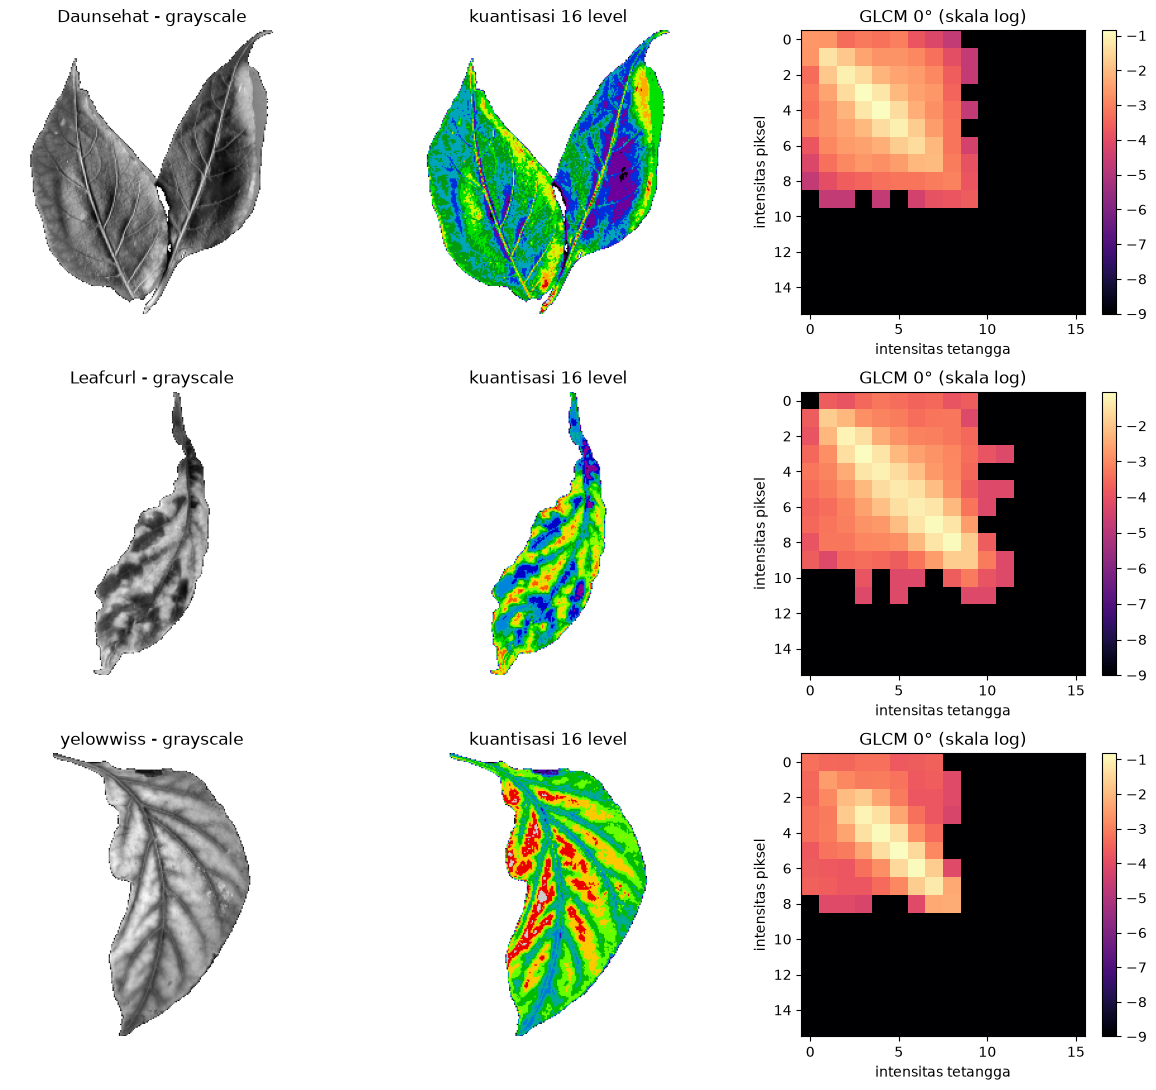

In [6]:
fig, ax = plt.subplots(3, 3, figsize=(12, 11))
for r, k in enumerate(KELAS):
    rgb, mask = data[k]
    gray, q = ke_gray_kuantisasi(rgb)
    ax[r, 0].imshow(np.where(mask, gray, np.nan), cmap="gray"); ax[r, 0].set_title(f"{k} - grayscale")
    ax[r, 1].imshow(np.where(mask, q, np.nan), cmap="nipy_spectral"); ax[r,  1].set_title(f"kuantisasi {LEVEL} level")
    P = glcm(q, mask, 0, 1)
    im = ax[r, 2].imshow(np.log10(P + 1e-9), cmap="magma"); ax[r, 2].set_title("GLCM 0° (skala log)")
    ax[r, 2].set_xlabel("intensitas tetangga"); ax[r, 2].set_ylabel("intensitas piksel")
    plt.colorbar(im, ax=ax[r, 2], fraction=0.046)
    ax[r, 0].axis("off"); ax[r, 1].axis("off")
plt.tight_layout(); plt.show()

**Cara baca GLCM:** titik terang yang menempel di diagonal = tetangga berintensitas mirip (halus). Titik yang menyebar jauh dari diagonal = banyak perubahan tajam (kasar, bercak, tepi).

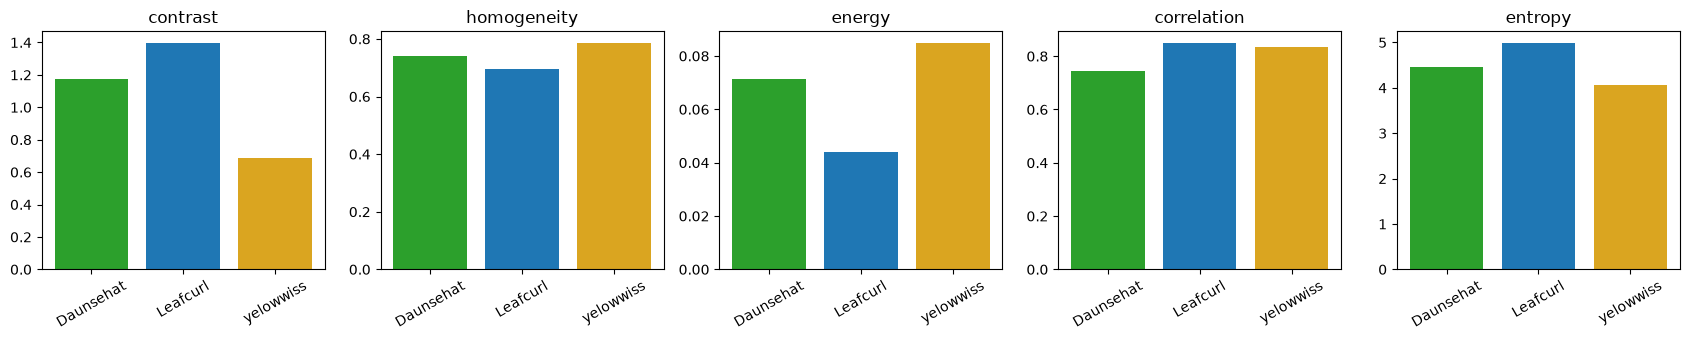

,glcm_contrast,glcm_homogeneity,glcm_energy,glcm_correlation,glcm_entropy
Daunsehat,1.1772,0.7408,0.0713,0.7459,4.4516
Leafcurl,1.3989,0.6957,0.0438,0.8508,4.9953
yelowwiss,0.6855,0.7870,0.0850,0.8348,4.0610


In [7]:
tabel_tekstur = pd.DataFrame({k: fitur_tekstur(*data[k]) for k in KELAS}).T
fig, ax = plt.subplots(1, 5, figsize=(17, 3.5))
for a, kol in zip(ax, tabel_tekstur.columns):
    a.bar(KELAS, tabel_tekstur[kol], color=[WARNA_KELAS[k] for k in KELAS])
    a.set_title(kol.replace("glcm_", "")); a.tick_params(axis="x", rotation=30)
plt.tight_layout(); plt.show()
tabel_tekstur.round(4)

## 5. Ekstraksi semua data
Memproses `train_asli` dan `train_aug`. Hasilnya disimpan di **dua CSV terpisah** (`fitur_train_asli.csv` dan `fitur_train_aug.csv`), satu baris per gambar.

In [8]:
hasil, gagal = {}, []
os.makedirs(OUT_DIR, exist_ok=True)
for sumber in SUMBER:
    daftar = kumpulkan(sumber)
    baris = []
    for i, (path, label) in enumerate(daftar, 1):
        rgb, mask = baca(path)
        if rgb is None or mask.sum() < 50:
            gagal.append(path); continue
        f = {**fitur_warna(rgb, mask), **fitur_tekstur(rgb, mask)}
        baris.append({"file": os.path.basename(path), "sumber": sumber, "label": label, **f})
        if i % 200 == 0:
            print(f"[{sumber}] {i}/{len(daftar)}")
    hasil[sumber] = pd.DataFrame(baris)
    out = os.path.join(OUT_DIR, f"fitur_{sumber}.csv")      # satu CSV per sumber
    hasil[sumber].to_csv(out, index=False)
    print(f"[{sumber}] selesai -> {out} ({len(baris)} gambar)")

print(f"Dilewati (kosong/tidak terbaca): {len(gagal)}")

# gabungan hanya di memori (untuk grafik perbandingan di bagian 6), TIDAK disimpan ke file
df = pd.concat(hasil.values(), ignore_index=True)
df.groupby(["sumber", "label"]).size().unstack()

[train_asli] selesai -> Dataset\ekstraksi_fitur_v2\fitur_train_asli.csv (162 gambar)
[train_aug] 200/823
[train_aug] 400/823
[train_aug] 600/823
[train_aug] 800/823
[train_aug] selesai -> Dataset\ekstraksi_fitur_v2\fitur_train_aug.csv (822 gambar)
Dilewati (kosong/tidak terbaca): 1


label,Daunsehat,Leafcurl,yelowwiss
sumber,,,
train_asli,115,42,5
train_aug,293,273,256


## 6. Perbandingan 3 kelas (seluruh dataset)
Boxplot per kelas: kalau kotak-kotaknya **terpisah**, fitur itu bagus untuk klasifikasi. Kalau **tumpang tindih**, fitur itu kurang membedakan.

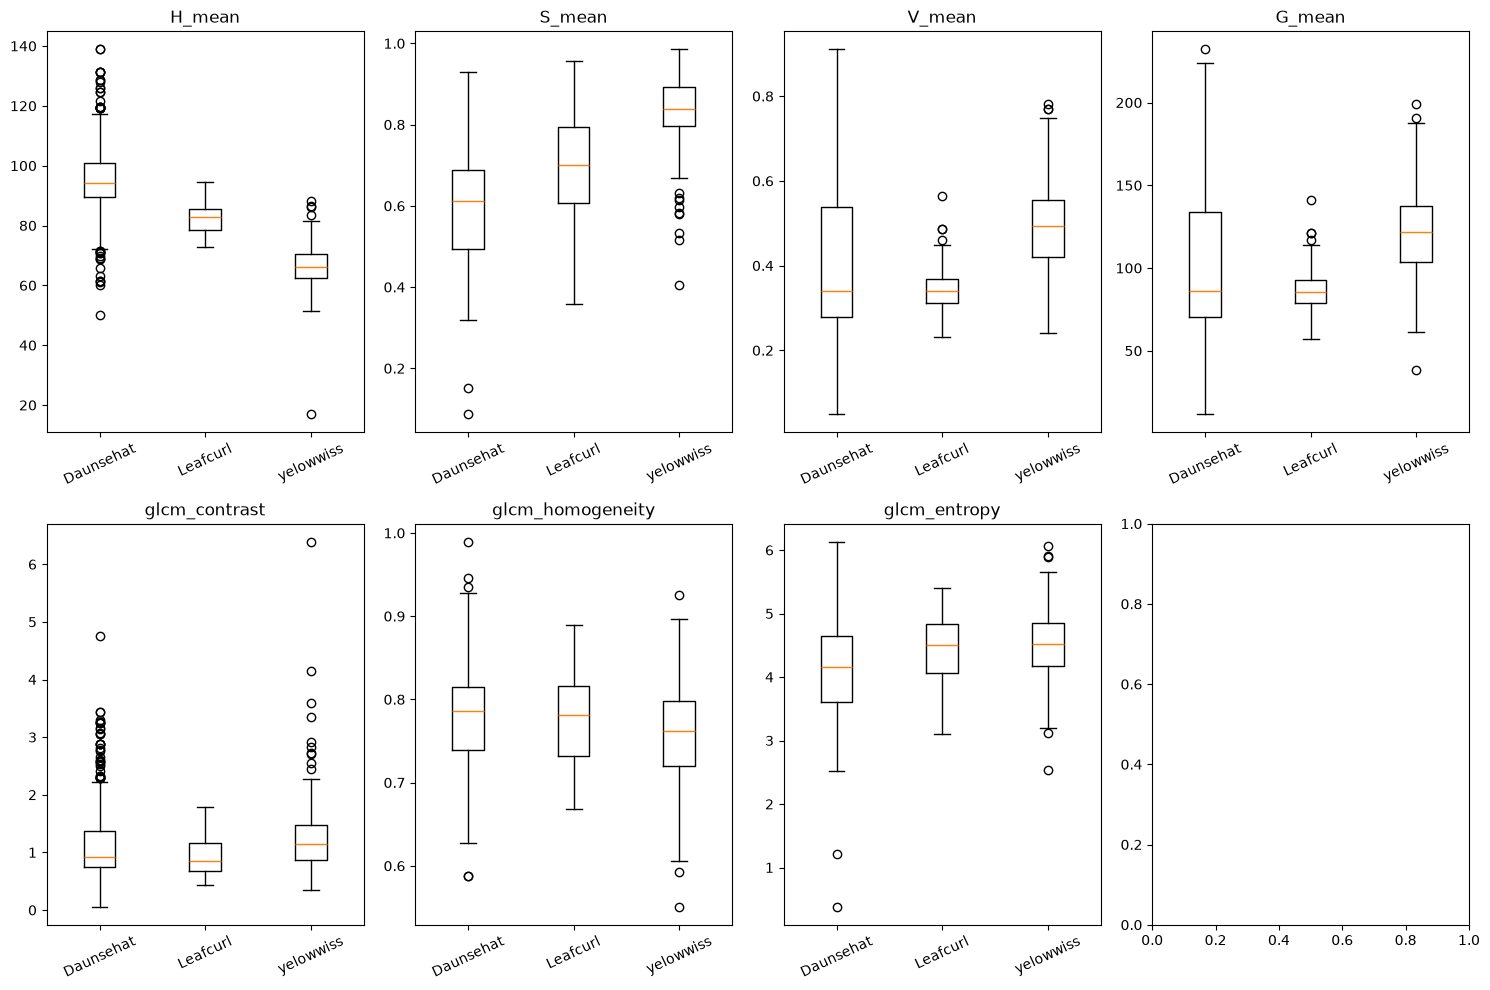

In [9]:
FITUR_KUNCI = ["H_mean", "S_mean", "V_mean", "G_mean",
               "glcm_contrast", "glcm_homogeneity", "glcm_entropy"]

fig, ax = plt.subplots(2, 4, figsize=(15, 10))
for a, f in zip(
    ax.ravel(), FITUR_KUNCI):
    a.boxplot([df.loc[df.label == k, f] for k in KELAS])
    a.set_xticks(range(1, len(KELAS) + 1)); a.set_xticklabels(KELAS)
    a.set_title(f); a.tick_params(axis="x", rotation=25)

plt.savefig("boxplot_fitur_kunci.png", dpi=300, bbox_inches="tight")
plt.tight_layout(); plt.show()

,H_mean,S_mean,V_mean,G_mean,glcm_contrast,glcm_homogeneity,glcm_entropy
label,,,,,,,
Daunsehat,95.669,0.595,0.405,102.064,1.152,0.777,4.192
Leafcurl,82.325,0.698,0.342,86.235,0.910,0.778,4.431
yelowwiss,66.536,0.835,0.496,123.346,1.242,0.758,4.506


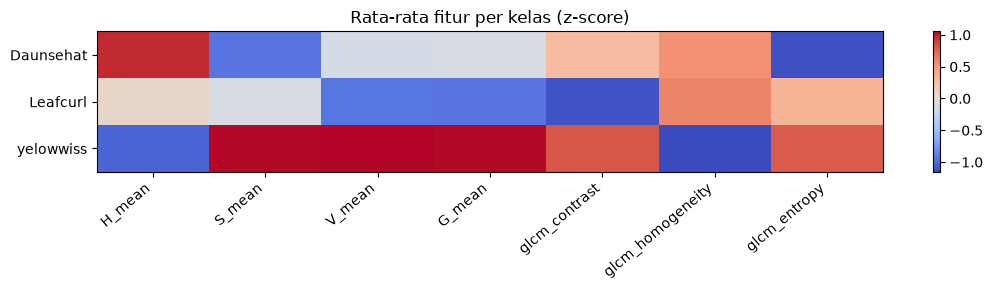

In [10]:
# Rata-rata fitur per kelas

rata = df.groupby("label").mean(numeric_only=True)[FITUR_KUNCI].loc[KELAS]
display(rata.round(3))

# Heatmap: rata-rata per kelas, distandarkan per fitur (z-score) supaya skala sebanding
z = (rata - rata.mean()) / rata.std().replace(0, 1)
fig, ax = plt.subplots(figsize=(11, 3))
im = ax.imshow(z.values, cmap="coolwarm", aspect="auto")
ax.set_xticks(range(len(FITUR_KUNCI))); ax.set_xticklabels(FITUR_KUNCI, rotation=40, ha="right")
ax.set_yticks(range(len(KELAS))); ax.set_yticklabels(KELAS)
plt.colorbar(im, ax=ax); ax.set_title("Rata-rata fitur per kelas (z-score)")
plt.tight_layout(); plt.show()

## 7. Kesimpulan (isi sendiri setelah melihat grafik)
- Fitur warna yang paling membedakan kelas: ...
- Fitur tekstur yang paling membedakan kelas: ...
- Fitur yang tumpang tindih / kurang berguna: ...

**Langkah berikutnya:** cek duplikat hasil augmentasi, split data, normalisasi (StandardScaler), lalu klasifikasi.